<a href="https://colab.research.google.com/github/Chuuya1124/APM1220/blob/main/SA1_Awit%2C_Julia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **APM1220 – Summative Assessment 1: MANOVA, PCA and Exploratory Factor Analysis**



## Setup

In [1]:
import os, sys, subprocess, warnings, urllib.request
warnings.filterwarnings("ignore")

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

try:
    import factor_analyzer
except ImportError:
    pip_install("factor_analyzer")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity
import factor_analyzer.factor_analyzer as fa_module

# factor_analyzer and recent scikit-learn disagree on one argument name; this keeps both working
_check = fa_module.check_array
def _check_compat(*a, **k):
    try:
        return _check(*a, **k)
    except TypeError:
        k["ensure_all_finite"] = k.pop("force_all_finite", True)
        return _check(*a, **k)
fa_module.check_array = _check_compat

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
PALETTE = {"Red": "#a4161a", "White": "#d4a017"}

for folder in ["data", "output/figures", "output/tables", "report"]:
    os.makedirs(folder, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f"output/figures/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def show(df, name, digits=3):
    df.to_csv(f"output/tables/{name}.csv")
    print(f"\n{name}\n" + df.round(digits).to_string())

def fmt_p(p):
    return "p < .001" if p < .001 else "p = " + f"{p:.3f}".lstrip("0")

## Part A. Data Preparation and Exploratory Analysis
**What I do:** load the red and white wine data, combine them, label each wine by colour, and check the data
quality (size, missing values, duplicates, outliers) before running any model.

In [2]:
BASE = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/"

try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    pip_install("ucimlrepo")
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        fetch_ucirepo = None

def load_from_ucimlrepo():
    data = fetch_ucirepo(id=186).data.original.copy()
    data["color"] = data["color"].astype(str).str.strip().str.capitalize()
    return data

def load_from_csv():
    parts = []
    for fname, color in [("winequality-red.csv", "Red"), ("winequality-white.csv", "White")]:
        path = f"data/{fname}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(BASE + fname, path)
        part = pd.read_csv(path, sep=";")
        part["color"] = color
        parts.append(part)
    return pd.concat(parts, ignore_index=True)

try:
    wine = load_from_ucimlrepo()
except Exception as err:
    print("ucimlrepo unavailable, downloading CSV files instead:", err)
    wine = load_from_csv()

wine.columns = [c.replace(" ", "_") for c in wine.columns]
wine = wine[wine["color"].isin(["Red", "White"])].reset_index(drop=True)
wine[wine.color == "Red"].drop(columns="color").to_csv("data/winequality-red.csv", sep=";", index=False)
wine[wine.color == "White"].drop(columns="color").to_csv("data/winequality-white.csv", sep=";", index=False)
wine["color"] = pd.Categorical(wine["color"], categories=["Red", "White"])

VARS = ["fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides",
        "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "pH", "sulphates", "alcohol"]

print("Wines:", len(wine), "| Variables:", wine.shape[1])
print(wine["color"].value_counts().to_string())
print("\nMissing values:", int(wine.isna().sum().sum()))
print("Exact duplicate rows:", int(wine.duplicated().sum()), "(kept in the analysis)")
wine.info()

Wines: 6497 | Variables: 13
color
White    4898
Red      1599

Missing values: 0
Exact duplicate rows: 1177 (kept in the analysis)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   fixed_acidity         6497 non-null   float64 
 1   volatile_acidity      6497 non-null   float64 
 2   citric_acid           6497 non-null   float64 
 3   residual_sugar        6497 non-null   float64 
 4   chlorides             6497 non-null   float64 
 5   free_sulfur_dioxide   6497 non-null   float64 
 6   total_sulfur_dioxide  6497 non-null   float64 
 7   density               6497 non-null   float64 
 8   pH                    6497 non-null   float64 
 9   sulphates             6497 non-null   float64 
 10  alcohol               6497 non-null   float64 
 11  quality               6497 non-null   int64   
 12  color                 6497 no

**Outliers.** Two checks: (1) the *1.5 × IQR rule* flags unusual values on one variable at a time;
(2) *Mahalanobis distance* flags wines that are unusual when all variables are considered together
(a wine is flagged if its distance is beyond the 99.9% limit of a chi-square distribution).
Outliers are reported, not deleted; later we check that conclusions do not depend on them.

In [3]:
def iqr_outliers(x):
    q1, q3 = x.quantile([.25, .75])
    return int(((x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))).sum())

def mahalanobis_sq(X):
    centred = X - X.mean(axis=0)
    inv_cov = np.linalg.inv(np.cov(X, rowvar=False))
    return np.einsum("ij,jk,ik->i", centred, inv_cov, centred)

out = wine.groupby("color")[VARS].agg(iqr_outliers).T
out["Total"] = out.sum(axis=1)
out["% of wines"] = 100 * out["Total"] / len(wine)
show(out, "A1_univariate_outliers", 2)

wine["mv_outlier"] = False
limit = stats.chi2.ppf(.999, len(VARS))
for c in ["Red", "White"]:
    rows = wine["color"] == c
    wine.loc[rows, "mv_outlier"] = mahalanobis_sq(wine.loc[rows, VARS].values) > limit
print("\nMultivariate outliers (all 11 variables):")
print(wine.groupby("color")["mv_outlier"].sum().to_string())


A1_univariate_outliers
color                 Red  White  Total  % of wines
fixed_acidity          49    119    168        2.59
volatile_acidity       19    186    205        3.16
citric_acid             1    270    271        4.17
residual_sugar        155      7    162        2.49
chlorides             112    208    320        4.93
free_sulfur_dioxide    30     50     80        1.23
total_sulfur_dioxide   55     19     74        1.14
density                45      5     50        0.77
pH                     35     75    110        1.69
sulphates              59    124    183        2.82
alcohol                13      0     13        0.20

Multivariate outliers (all 11 variables):
color
Red       60
White    137


**Descriptive statistics.** Mean, spread, skewness and the coefficient of variation (CV = SD ÷ mean, which lets us
compare variability across variables measured on different scales).

In [4]:
desc = wine[VARS].describe().T
desc["skew"] = wine[VARS].skew()
desc["CV_%"] = 100 * desc["std"] / desc["mean"]
show(desc, "A2_descriptives")
show(wine.groupby("color")[VARS].mean().T, "A3_means_by_color")
print("\nMost variable relative to their mean (CV %):")
print(desc["CV_%"].sort_values(ascending=False).head(5).round(1).to_string())


A2_descriptives
                       count     mean     std    min     25%      50%      75%      max   skew    CV_%
fixed_acidity         6497.0    7.215   1.296  3.800   6.400    7.000    7.700   15.900  1.723  17.968
volatile_acidity      6497.0    0.340   0.165  0.080   0.230    0.290    0.400    1.580  1.495  48.470
citric_acid           6497.0    0.319   0.145  0.000   0.250    0.310    0.390    1.660  0.472  45.607
residual_sugar        6497.0    5.443   4.758  0.600   1.800    3.000    8.100   65.800  1.435  87.408
chlorides             6497.0    0.056   0.035  0.009   0.038    0.047    0.065    0.611  5.400  62.522
free_sulfur_dioxide   6497.0   30.525  17.749  1.000  17.000   29.000   41.000  289.000  1.220  58.146
total_sulfur_dioxide  6497.0  115.745  56.522  6.000  77.000  118.000  156.000  440.000 -0.001  48.833
density               6497.0    0.995   0.003  0.987   0.992    0.995    0.997    1.039  0.504   0.301
pH                    6497.0    3.219   0.161  2.720   3

**Distributions and colour comparison.** Histograms show the shape of each variable; boxplots show how red and
white wines differ.

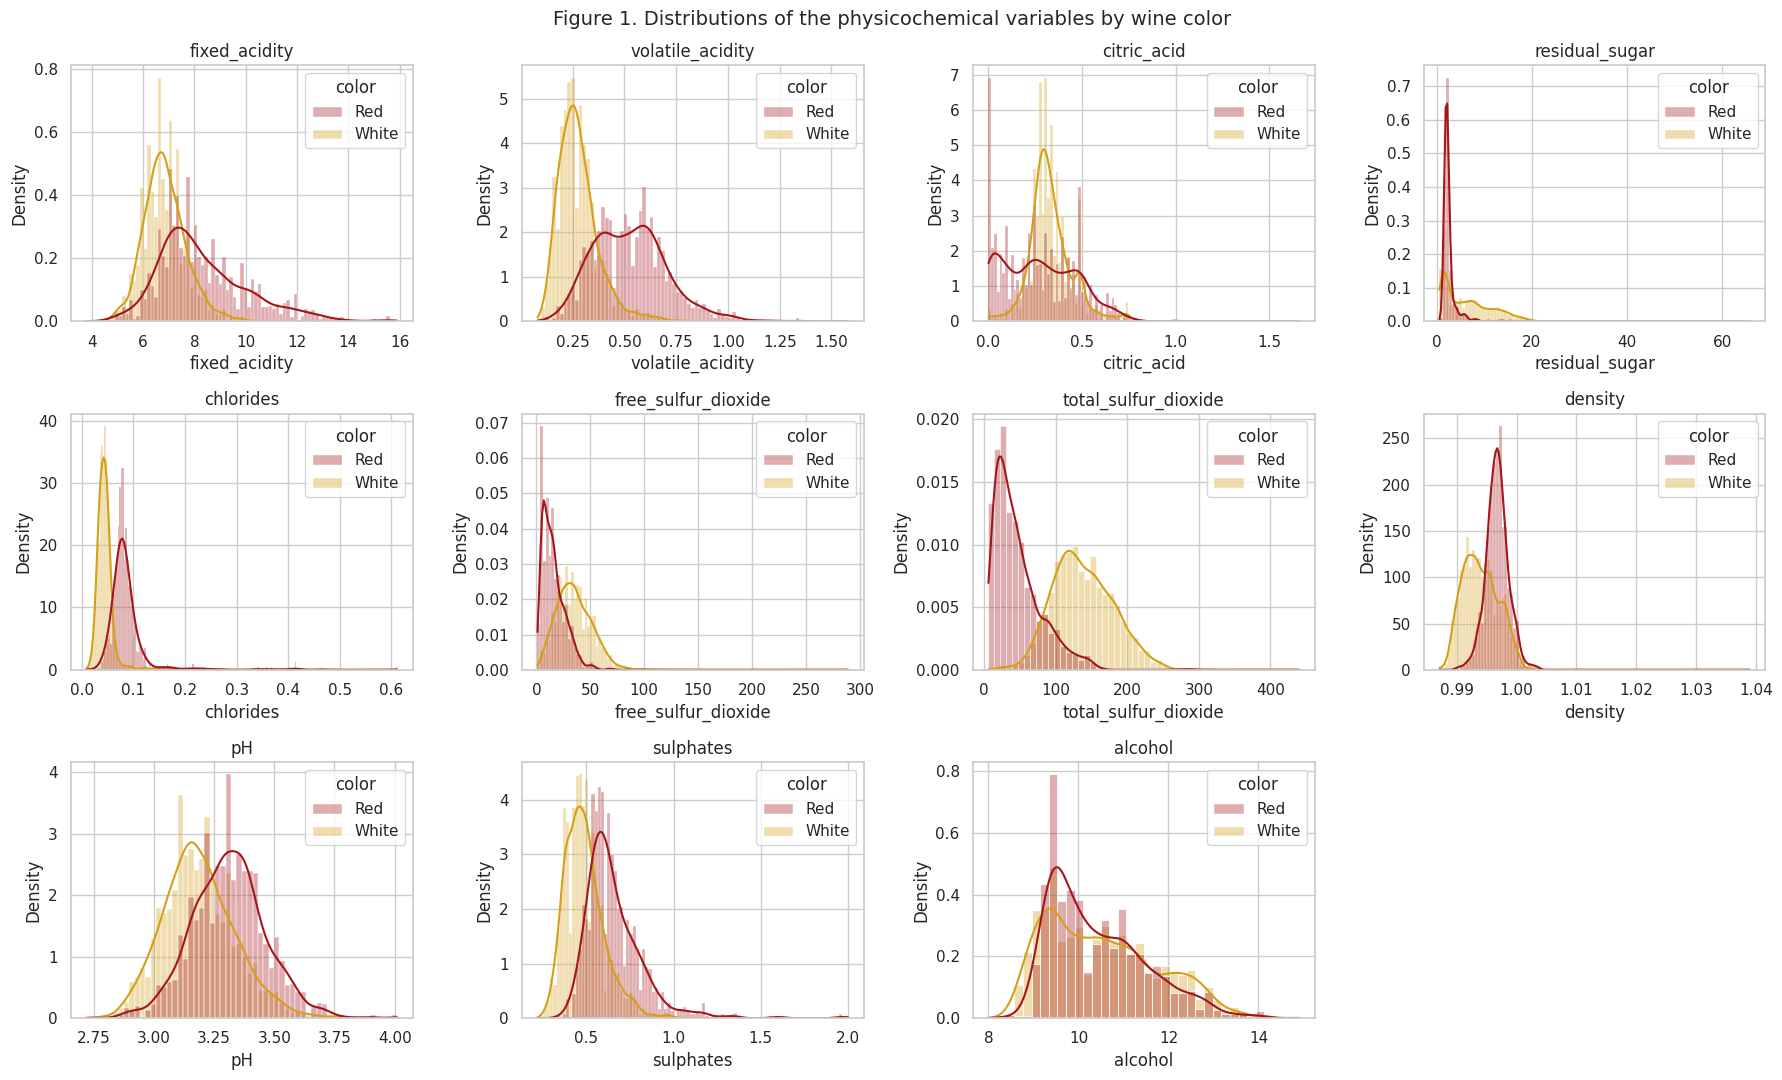

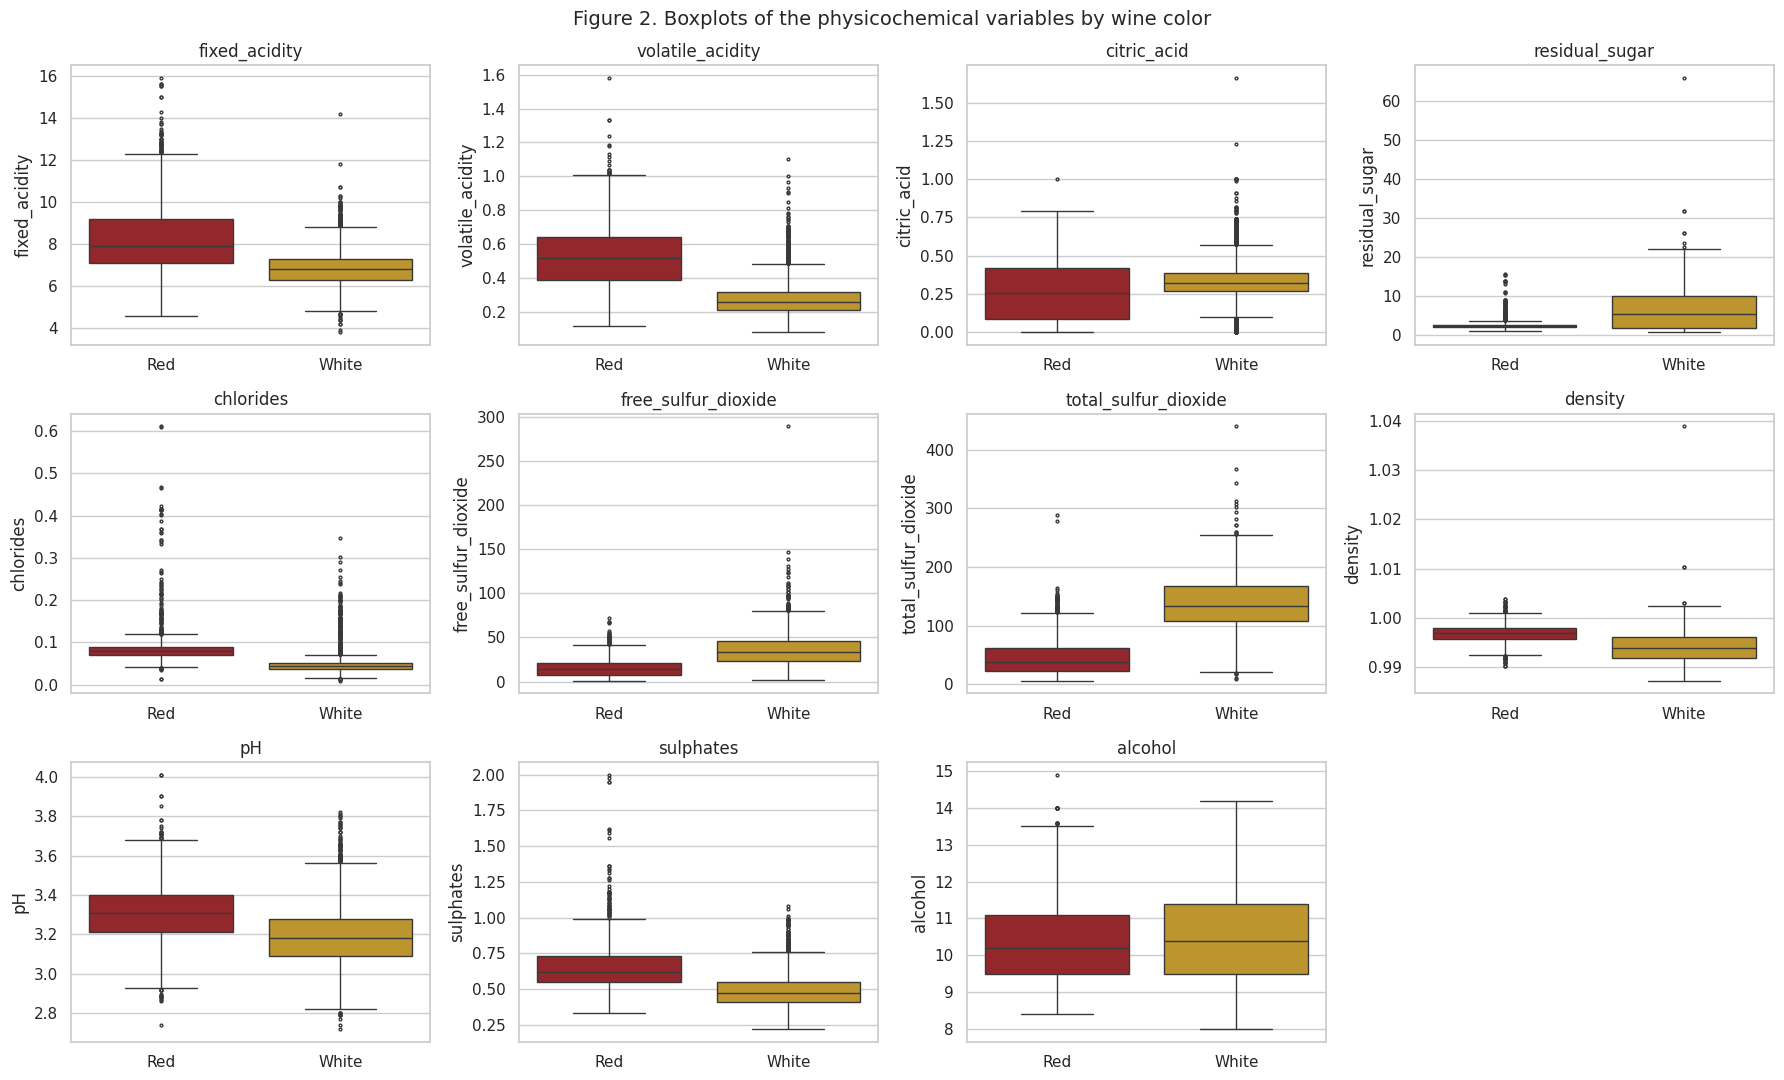

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), VARS):
    sns.histplot(data=wine, x=v, hue="color", kde=True, stat="density", common_norm=False,
                 palette=PALETTE, alpha=.35, ax=ax)
    ax.set_title(v)
axes.ravel()[-1].axis("off")
fig.suptitle("Figure 1. Distributions of the physicochemical variables by wine color", fontsize=14)
save_fig("fig01_histograms")

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.ravel(), VARS):
    sns.boxplot(data=wine, x="color", y=v, palette=PALETTE, fliersize=2, ax=ax)
    ax.set_title(v); ax.set_xlabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Figure 2. Boxplots of the physicochemical variables by wine color", fontsize=14)
save_fig("fig02_boxplots")

**Correlations.** Values near +1 or −1 mean two variables move together closely. Strong correlations matter
because PCA and factor analysis work by grouping variables that move together.


A4_correlation_matrix
                      fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  free_sulfur_dioxide  total_sulfur_dioxide  density    pH  sulphates  alcohol
fixed_acidity                  1.00              0.22         0.32           -0.11       0.30                -0.28                 -0.33     0.46 -0.25       0.30    -0.10
volatile_acidity               0.22              1.00        -0.38           -0.20       0.38                -0.35                 -0.41     0.27  0.26       0.23    -0.04
citric_acid                    0.32             -0.38         1.00            0.14       0.04                 0.13                  0.20     0.10 -0.33       0.06    -0.01
residual_sugar                -0.11             -0.20         0.14            1.00      -0.13                 0.40                  0.50     0.55 -0.27      -0.19    -0.36
chlorides                      0.30              0.38         0.04           -0.13       1.00                -0.20   

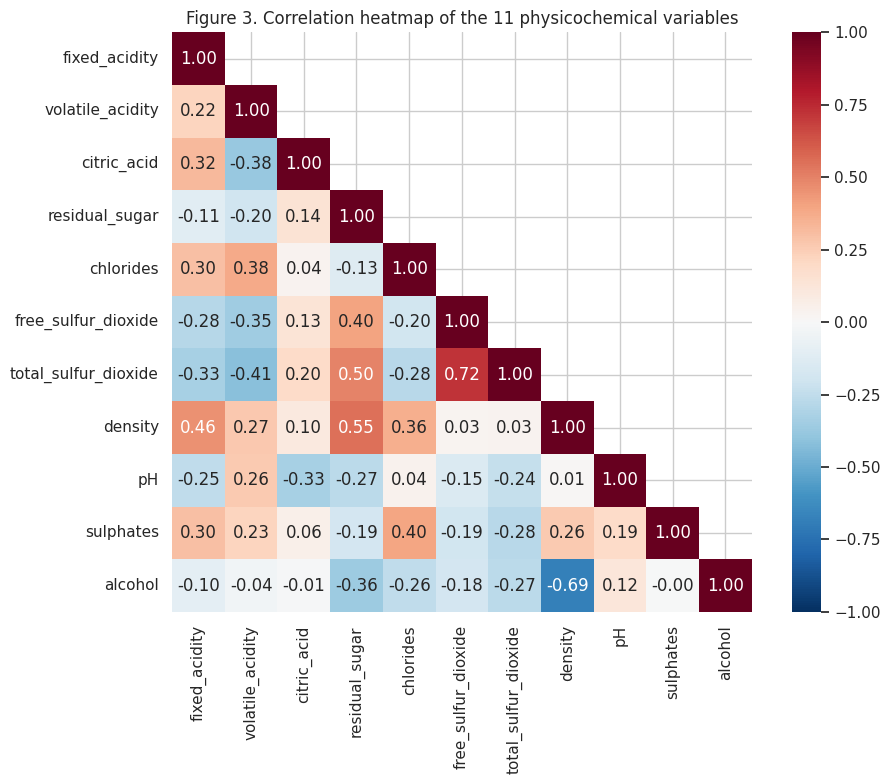


Strongest correlations:
          variable 1          variable 2     r
total_sulfur_dioxide free_sulfur_dioxide  0.72
             alcohol             density -0.69
             density      residual_sugar  0.55
total_sulfur_dioxide      residual_sugar  0.50
             density       fixed_acidity  0.46
total_sulfur_dioxide    volatile_acidity -0.41


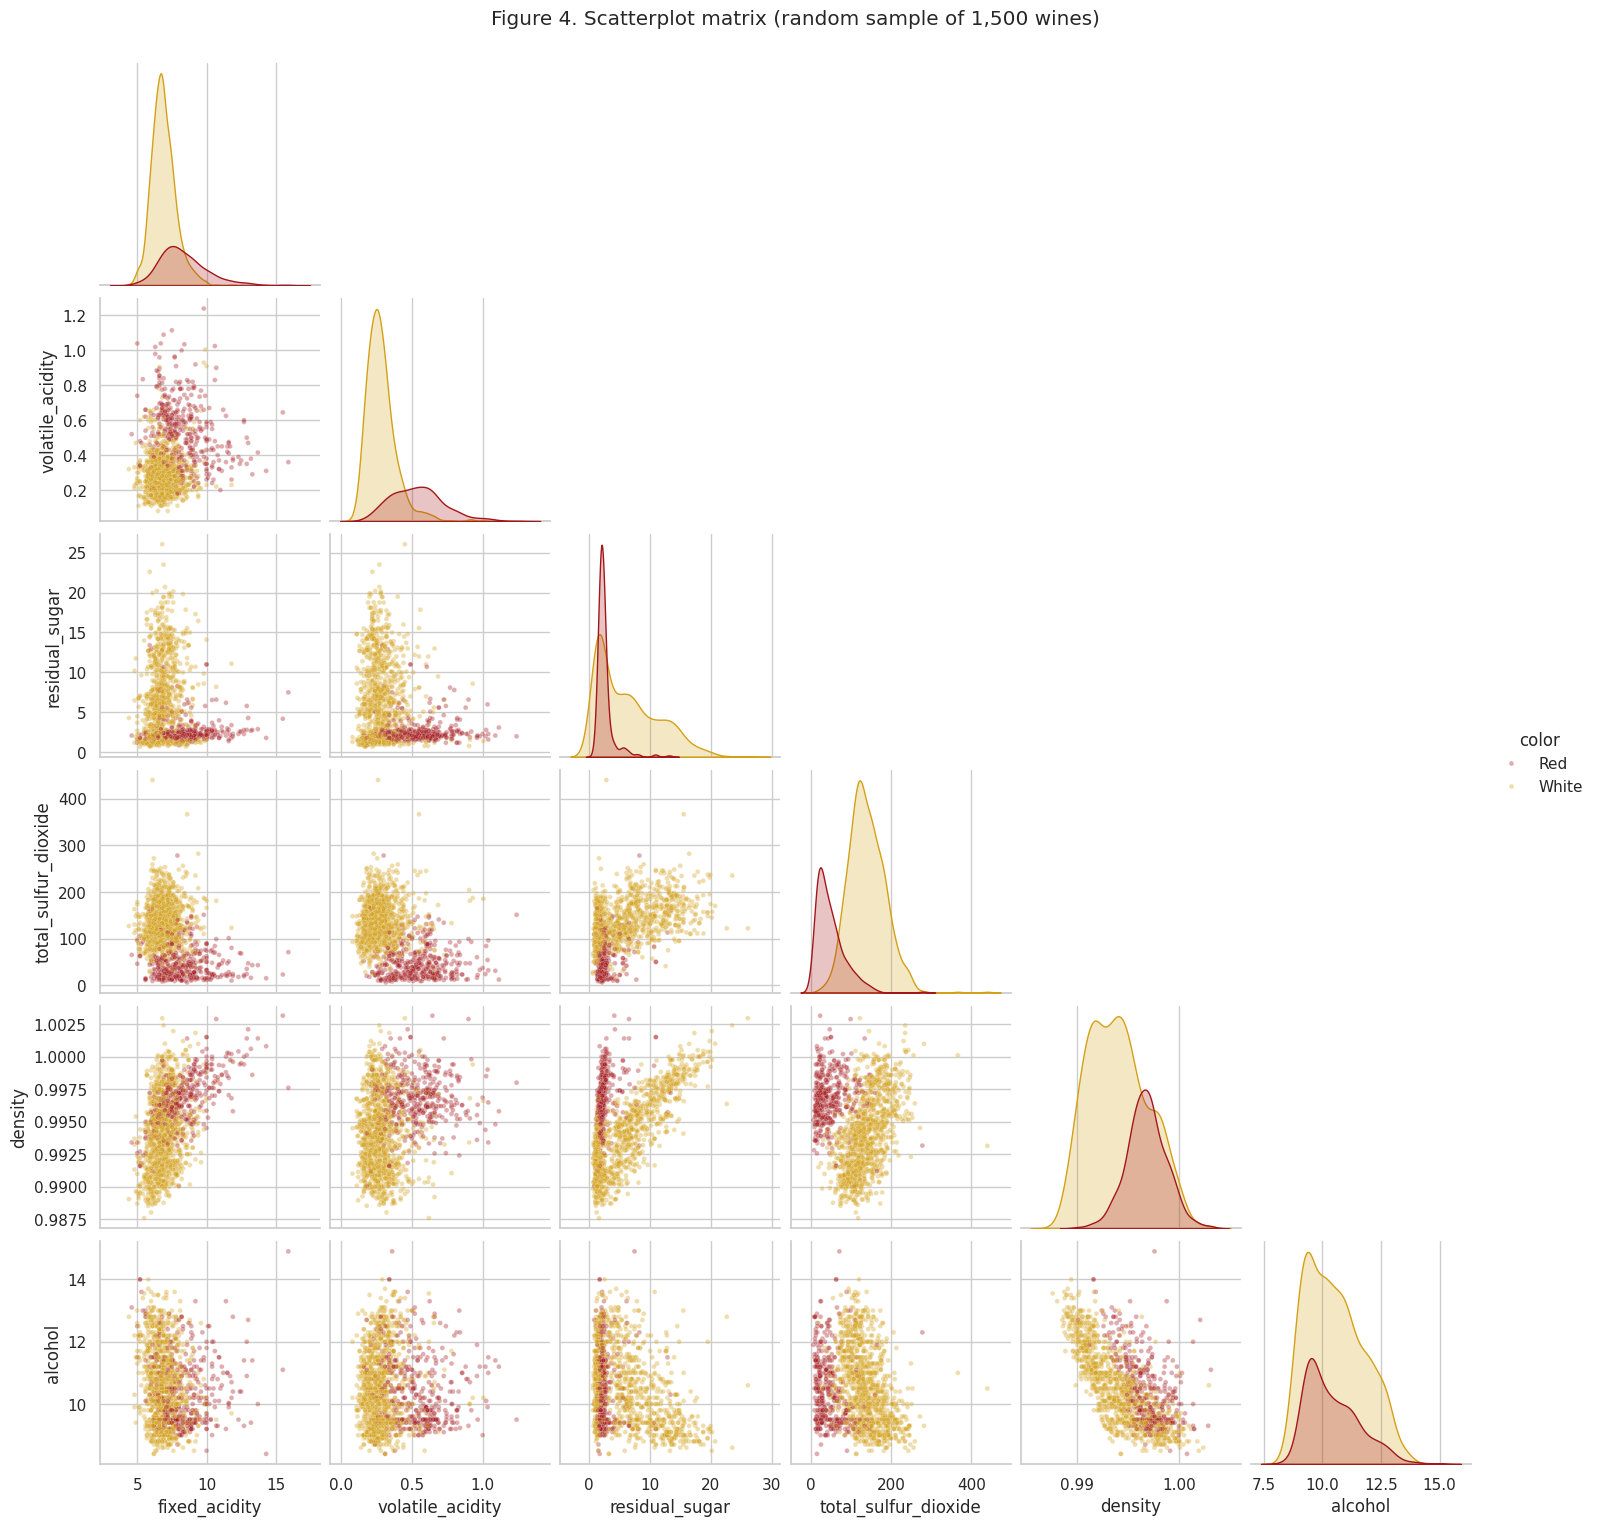

In [6]:
corr = wine[VARS].corr()
show(corr, "A4_correlation_matrix", 2)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True)
plt.title("Figure 3. Correlation heatmap of the 11 physicochemical variables")
save_fig("fig03_correlation_heatmap")

pairs = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().reset_index()
pairs.columns = ["variable 1", "variable 2", "r"]
print("\nStrongest correlations:")
print(pairs.reindex(pairs["r"].abs().sort_values(ascending=False).index).head(6).round(2).to_string(index=False))

g = sns.pairplot(wine.sample(1500, random_state=SEED), hue="color", palette=PALETTE, corner=True,
                 vars=["fixed_acidity", "volatile_acidity", "residual_sugar", "total_sulfur_dioxide", "density", "alcohol"],
                 plot_kws={"alpha": .35, "s": 12})
g.fig.suptitle("Figure 4. Scatterplot matrix (random sample of 1,500 wines)", y=1.02)
g.fig.savefig("output/figures/fig04_scatterplot_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

## Part B. MANOVA: Do red and white wines differ overall?
**Idea:** an ANOVA compares groups on *one* outcome. A MANOVA compares groups on *several outcomes at once*,
asking whether the whole pattern of average values (the "mean vector") differs between red and white wines.

- **H₀:** red and white wines have the same mean vector on the chosen variables.
- **H₁:** the mean vectors are different.

**Choosing the outcome variables.** I chose seven variables that cover different aspects of wine chemistry:
*acidity* (fixed, volatile), *sweetness* (residual sugar), *saltiness* (chlorides), *preservation*
(total sulfur dioxide, sulphates) and *strength* (alcohol). I left out `density` (almost fully determined by alcohol and
sugar) and `free_sulfur_dioxide` (largely repeats total sulfur dioxide) so the outcomes are related but not duplicates.

In [7]:
DVS = ["fixed_acidity", "volatile_acidity", "residual_sugar", "chlorides",
       "total_sulfur_dioxide", "sulphates", "alcohol"]

show(wine[DVS].corr(), "B1_outcome_correlations", 2)
X_vif = wine[DVS].assign(const=1.0).values
vif = pd.Series([variance_inflation_factor(X_vif, i) for i in range(len(DVS))], index=DVS, name="VIF")
show(vif.to_frame(), "B2_VIF", 2)
print("\nVIF below about 5 means no variable is a near-copy of the others.")


B1_outcome_correlations
                      fixed_acidity  volatile_acidity  residual_sugar  chlorides  total_sulfur_dioxide  sulphates  alcohol
fixed_acidity                  1.00              0.22           -0.11       0.30                 -0.33       0.30    -0.10
volatile_acidity               0.22              1.00           -0.20       0.38                 -0.41       0.23    -0.04
residual_sugar                -0.11             -0.20            1.00      -0.13                  0.50      -0.19    -0.36
chlorides                      0.30              0.38           -0.13       1.00                 -0.28       0.40    -0.26
total_sulfur_dioxide          -0.33             -0.41            0.50      -0.28                  1.00      -0.28    -0.27
sulphates                      0.30              0.23           -0.19       0.40                 -0.28       1.00    -0.00
alcohol                       -0.10             -0.04           -0.36      -0.26                 -0.27      -0.00 

### Checking the assumptions
| Assumption | Meaning | How we check it |
|---|---|---|
| Independence | each wine is a separate sample | study design (each row is a different wine) |
| Multivariate normality | the outcomes together follow a bell-shaped pattern | Mardia's tests, Q-Q plots |
| No extreme multivariate outliers | no wines that are very unusual overall | Mahalanobis distance |
| Equal covariance matrices | red and white have a similar spread and relationships | Box's M, Levene's test |
| Related outcomes | outcomes are related but not duplicates | correlations, VIF (above) |


B3_univariate_normality
    color              variable    skew  excess_kurtosis  Shapiro_W    p
0     Red         fixed_acidity  0.9828           1.1321     0.9420  0.0
1     Red      volatile_acidity  0.6716           1.2255     0.9743  0.0
2     Red        residual_sugar  4.5407          28.6176     0.5661  0.0
3     Red             chlorides  5.6803          41.7158     0.4842  0.0
4     Red  total_sulfur_dioxide  1.5155           3.8098     0.8732  0.0
5     Red             sulphates  2.4287          11.7203     0.8330  0.0
6     Red               alcohol  0.8608           0.2000     0.9288  0.0
7   White         fixed_acidity  0.6478           2.1722     0.9766  0.0
8   White      volatile_acidity  1.5770           5.0916     0.9045  0.0
9   White        residual_sugar  1.0771           3.4698     0.8846  0.0
10  White             chlorides  5.0233          37.5646     0.5908  0.0
11  White  total_sulfur_dioxide  0.3907           0.5719     0.9890  0.0
12  White             sulp

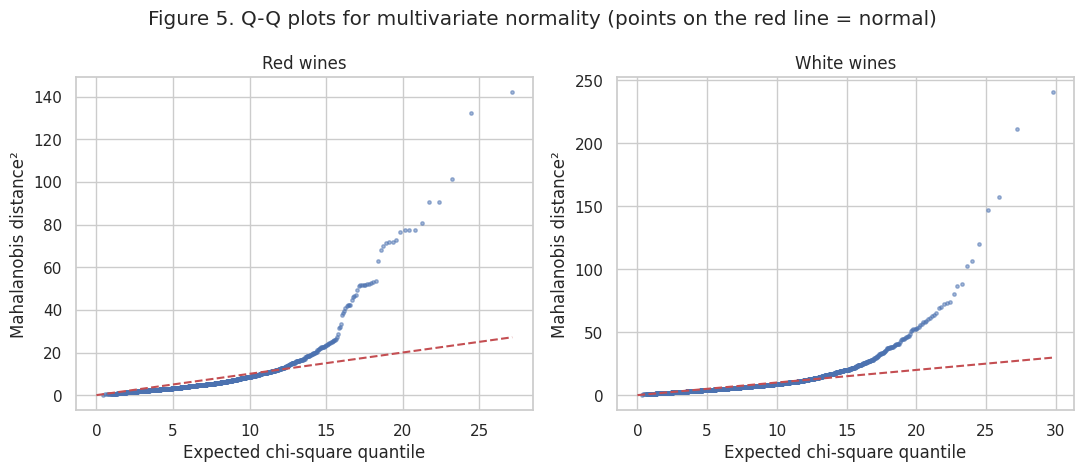


Multivariate outliers on the 7 outcome variables:
color
Red       52
White    120

Box's M = 7679.9, chi-square(28) = 7667.2, p < .001

B5_levene_tests
                       Levene_W    p
fixed_acidity          942.3294  0.0
volatile_acidity       851.8751  0.0
residual_sugar        1867.5440  0.0
chlorides              123.9688  0.0
total_sulfur_dioxide   181.3812  0.0
sulphates              107.7430  0.0
alcohol                 72.7846  0.0


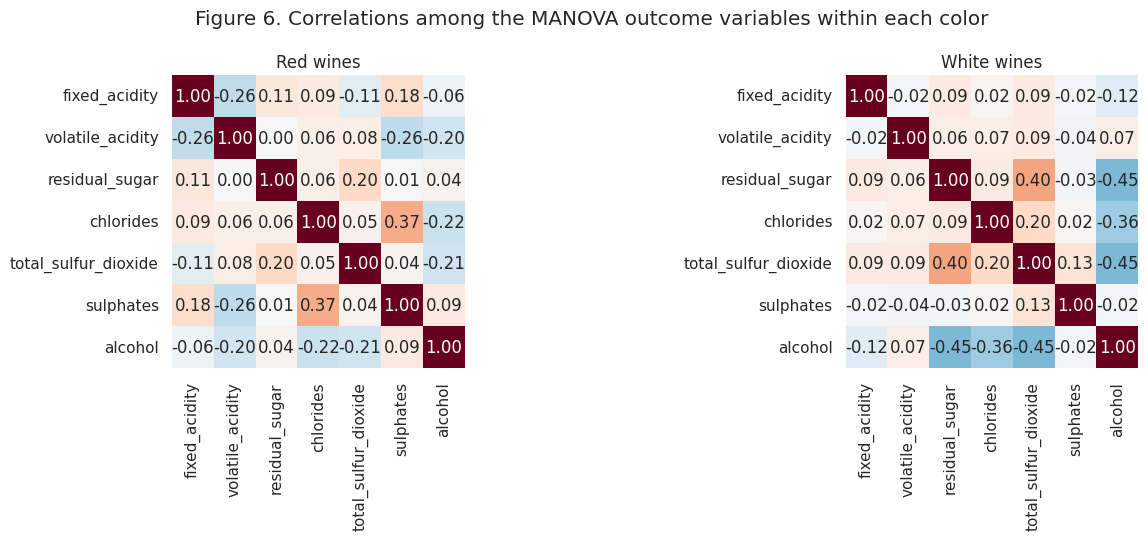

In [8]:
norm_rows = []
for c in ["Red", "White"]:
    for v in DVS:
        x = wine.loc[wine.color == c, v]
        w, p = stats.shapiro(x.sample(min(len(x), 5000), random_state=SEED))
        norm_rows.append([c, v, x.skew(), x.kurt(), w, p])
show(pd.DataFrame(norm_rows, columns=["color", "variable", "skew", "excess_kurtosis", "Shapiro_W", "p"]),
     "B3_univariate_normality", 4)

def mardia(X):
    n, p = X.shape
    centred = X - X.mean(axis=0)
    D = centred @ np.linalg.inv(np.cov(X, rowvar=False, bias=True)) @ centred.T
    skew_stat = (D ** 3).sum() / n ** 2 * n / 6
    skew_df = p * (p + 1) * (p + 2) / 6
    kurt = (np.diag(D) ** 2).sum() / n
    z = (kurt - p * (p + 2)) / np.sqrt(8 * p * (p + 2) / n)
    return {"skewness_chi2": skew_stat, "skewness_df": skew_df, "skewness_p": stats.chi2.sf(skew_stat, skew_df),
            "kurtosis": kurt, "kurtosis_expected": p * (p + 2), "kurtosis_z": z, "kurtosis_p": 2 * stats.norm.sf(abs(z))}

show(pd.DataFrame({c: mardia(wine.loc[wine.color == c, DVS].values) for c in ["Red", "White"]}).T,
     "B4_mardia_tests", 4)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, c in zip(axes, ["Red", "White"]):
    d2 = np.sort(mahalanobis_sq(wine.loc[wine.color == c, DVS].values))
    q = stats.chi2.ppf((np.arange(1, len(d2) + 1) - .5) / len(d2), len(DVS))
    ax.scatter(q, d2, s=6, alpha=.5)
    ax.plot([0, q.max()], [0, q.max()], "r--")
    ax.set(title=f"{c} wines", xlabel="Expected chi-square quantile", ylabel="Mahalanobis distance²")
fig.suptitle("Figure 5. Q-Q plots for multivariate normality (points on the red line = normal)")
save_fig("fig05_mv_normality")

limit_dv = stats.chi2.ppf(.999, len(DVS))
wine["mv_outlier_dv"] = False
for c in ["Red", "White"]:
    rows = wine["color"] == c
    wine.loc[rows, "mv_outlier_dv"] = mahalanobis_sq(wine.loc[rows, DVS].values) > limit_dv
print("\nMultivariate outliers on the 7 outcome variables:")
print(wine.groupby("color")["mv_outlier_dv"].sum().to_string())

def box_m(groups):
    k, p = len(groups), groups[0].shape[1]
    n = np.array([len(g) for g in groups]); N = n.sum()
    covs = [np.cov(g, rowvar=False) for g in groups]
    pooled = sum((ni - 1) * S for ni, S in zip(n, covs)) / (N - k)
    M = (N - k) * np.linalg.slogdet(pooled)[1] - sum((ni - 1) * np.linalg.slogdet(S)[1] for ni, S in zip(n, covs))
    c = (sum(1 / (n - 1)) - 1 / (N - k)) * (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    df = p * (p + 1) * (k - 1) / 2
    return M, M * (1 - c), df, stats.chi2.sf(M * (1 - c), df)

M, chi2_bm, df_bm, p_bm = box_m([wine.loc[wine.color == c, DVS].values for c in ["Red", "White"]])
print(f"\nBox's M = {M:.1f}, chi-square({df_bm:.0f}) = {chi2_bm:.1f}, {fmt_p(p_bm)}")

lev = pd.DataFrame([stats.levene(wine.loc[wine.color == "Red", v], wine.loc[wine.color == "White", v], center="median")
                    for v in DVS], index=DVS, columns=["Levene_W", "p"])
show(lev, "B5_levene_tests", 4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, c in zip(axes, ["Red", "White"]):
    sns.heatmap(wine.loc[wine.color == c, DVS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
    ax.set_title(f"{c} wines")
fig.suptitle("Figure 6. Correlations among the MANOVA outcome variables within each color")
save_fig("fig06_outcome_correlations")

**Reading the assumption results.** With thousands of wines, formal tests such as Shapiro-Wilk, Mardia and Box's M
almost always give *p* < .05 even for small, harmless departures, so we judge them together with the plots.
Right-skewed variables and unequal covariance matrices are expected here. We therefore use **Pillai's trace** as the
main test (the most robust MANOVA statistic when assumptions are imperfect and group sizes are unequal) and re-run the test
without the multivariate outliers to confirm the conclusion does not change.

### Running the MANOVA
The test statistics (Wilks' lambda, Pillai's trace, Hotelling-Lawley trace, Roy's root) all give the same answer
with only two groups. **Partial η²** is the effect size: the share of the combined variation explained by wine colour.

In [9]:
formula = " + ".join(DVS) + " ~ C(color)"
result = MANOVA.from_formula(formula, data=wine).mv_test().results["C(color)"]["stat"]
result["partial_eta2"] = np.nan
result.loc["Pillai's trace", "partial_eta2"] = result.loc["Pillai's trace", "Value"]
result.loc["Wilks' lambda", "partial_eta2"] = 1 - result.loc["Wilks' lambda", "Value"]
show(result, "B6_manova_tests", 4)

pt = result.loc["Pillai's trace"]
print(f"\nPillai's trace = {pt['Value']:.3f}, F({int(pt['Num DF'])}, {int(pt['Den DF'])}) = {pt['F Value']:.2f}, "
      f"{fmt_p(pt['Pr > F'])}, partial eta² = {pt['partial_eta2']:.3f}")

clean = wine[~wine["mv_outlier_dv"]]
pt2 = MANOVA.from_formula(formula, data=clean).mv_test().results["C(color)"]["stat"].loc["Pillai's trace"]
print(f"Without {int(wine['mv_outlier_dv'].sum())} outliers: Pillai's trace = {pt2['Value']:.3f}, "
      f"F = {pt2['F Value']:.2f}, {fmt_p(pt2['Pr > F'])}")

red_X = wine.loc[wine.color == "Red", DVS].values
white_X = wine.loc[wine.color == "White", DVS].values
pooled = ((len(red_X) - 1) * np.cov(red_X, rowvar=False) + (len(white_X) - 1) * np.cov(white_X, rowvar=False)) \
         / (len(red_X) + len(white_X) - 2)
diff = red_X.mean(0) - white_X.mean(0)
print(f"Distance between the red and white centroids: {np.sqrt(diff @ np.linalg.solve(pooled, diff)):.2f} "
      "pooled standard deviations")


B6_manova_tests
                           Value Num DF  Den DF      F Value Pr > F  partial_eta2
Wilks' lambda            0.22913      7  6489.0  3118.746006    0.0        0.7709
Pillai's trace           0.77087    7.0  6489.0  3118.746006    0.0        0.7709
Hotelling-Lawley trace  3.364343      7  6489.0  3118.746006    0.0           NaN
Roy's greatest root     3.364343      7    6489  3118.746006    0.0           NaN

Pillai's trace = 0.771, F(7, 6489) = 3118.75, p < .001, partial eta² = 0.771
Without 172 outliers: Pillai's trace = 0.817, F = 4016.08, p < .001
Distance between the red and white centroids: 4.26 pooled standard deviations


### Follow-up analyses: which variables drive the difference?
Because the MANOVA is significant, we run a one-way ANOVA on each variable (alpha is divided by 7 to avoid false
positives, the *Bonferroni* correction). **η²** and **Cohen's d** show the size of each difference
(|d| ≈ 0.2 small, 0.5 medium, 0.8 large). A discriminant analysis then shows which variables best separate red from white
*when used together*. No post-hoc tests are needed because there are only two groups.


B7_univariate_anovas
                      mean_red   sd_red  mean_white  sd_white          F       p    eta2  cohens_d  significant_after_Bonferroni
variable                                                                                                                        
fixed_acidity           8.3196   1.7411      6.8548    0.8439  2016.5101  0.0000  0.2369    1.2934                          True
volatile_acidity        0.5278   0.1791      0.2782    0.1008  4829.3171  0.0000  0.4265    2.0015                          True
residual_sugar          2.5388   1.4099      6.3914    5.0721   899.7663  0.0000  0.1217   -0.8639                          True
chlorides               0.0875   0.0471      0.0458    0.0218  2315.8295  0.0000  0.2628    1.3860                          True
total_sulfur_dioxide   46.4678  32.8953    138.3607   42.4981  6252.7956  0.0000  0.4905   -2.2775                          True
sulphates               0.6581   0.1695      0.4898    0.1141  2021.7075  0

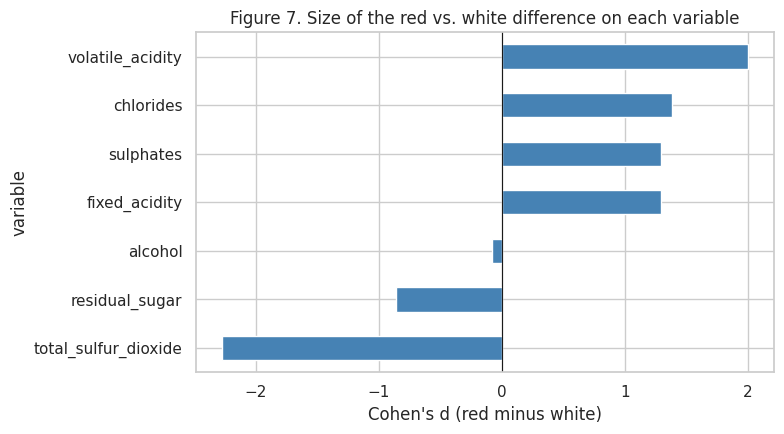

In [10]:
def cohens_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

rows = []
for v in DVS:
    a, b = wine.loc[wine.color == "Red", v], wine.loc[wine.color == "White", v]
    F, p = stats.f_oneway(a, b)
    df_err = len(a) + len(b) - 2
    rows.append([v, a.mean(), a.std(), b.mean(), b.std(), F, p, F / (F + df_err), cohens_d(a, b)])
uni = pd.DataFrame(rows, columns=["variable", "mean_red", "sd_red", "mean_white", "sd_white", "F", "p", "eta2", "cohens_d"]
                   ).set_index("variable")
uni["significant_after_Bonferroni"] = uni["p"] < .05 / len(DVS)
show(uni, "B7_univariate_anovas", 4)

Z = StandardScaler().fit_transform(wine[DVS])
lda = LinearDiscriminantAnalysis().fit(Z, wine["color"])
scores = lda.transform(Z)[:, 0]
dfa = pd.DataFrame({"discriminant_weight": lda.scalings_[:, 0] / np.abs(lda.scalings_[:, 0]).max(),
                    "correlation_with_function": [np.corrcoef(Z[:, j], scores)[0, 1] for j in range(len(DVS))]}, index=DVS)
show(dfa.sort_values("correlation_with_function", key=np.abs, ascending=False), "B8_discriminant_analysis")
print(f"\nColor correctly classified from these 7 variables: {lda.score(Z, wine['color']):.1%}")

plt.figure(figsize=(8, 4.5))
uni["cohens_d"].sort_values().plot.barh(color="steelblue")
plt.axvline(0, color="k", lw=.8)
plt.xlabel("Cohen's d (red minus white)")
plt.title("Figure 7. Size of the red vs. white difference on each variable")
save_fig("fig07_cohens_d")

## Part C. Principal Component Analysis (PCA)
**Idea:** PCA combines the 11 correlated variables into a few new, uncorrelated summary scores called *principal
components* (PCs). PC1 captures as much of the total variation as possible, PC2 the most of what is left, and so on.

**Step 1 – Is PCA suitable?** Bartlett's test checks that the variables are correlated at all, and the KMO
measure checks that the correlations are strong enough to form groups (KMO ≥ .60 is acceptable).

In [11]:
X = wine[VARS]
chi2_b, p_b = calculate_bartlett_sphericity(X)
kmo_each, kmo_all = calculate_kmo(X)
R = X.corr().values
print(f"Bartlett's test: chi-square(55) = {chi2_b:.1f}, {fmt_p(p_b)}")
print(f"Overall KMO = {kmo_all:.2f}")
print(f"Determinant of the correlation matrix = {np.linalg.det(R):.4f} (above 0.00001: no extreme overlap)")
show(pd.Series(kmo_each, index=VARS, name="KMO").to_frame(), "C1_kmo_per_variable", 2)

Bartlett's test: chi-square(55) = 37094.6, p < .001
Overall KMO = 0.41
Determinant of the correlation matrix = 0.0033 (above 0.00001: no extreme overlap)

C1_kmo_per_variable
                       KMO
fixed_acidity         0.28
volatile_acidity      0.61
citric_acid           0.62
residual_sugar        0.29
chlorides             0.73
free_sulfur_dioxide   0.75
total_sulfur_dioxide  0.72
density               0.30
pH                    0.21
sulphates             0.56
alcohol               0.27


**Step 2 – Standardise.** The variables use very different units (total sulfur dioxide runs up to hundreds of mg/L,
density is about 0.99 g/cm³). Without standardising, PCA would only reflect the variables with the biggest numbers.
Converting each variable to a z-score (mean 0, SD 1) gives every variable an equal say; this is the same as running PCA
on the correlation matrix.

In [12]:
Zs = StandardScaler().fit_transform(X)

**Step 3 – How many components?** I use several tools together rather than a single rule:
- **Eigenvalue:** how much variance a component captures (a value above 1 means it beats a single original variable).
- **Scree plot:** look for the "elbow" where the curve flattens.
- **Variance explained:** how much of the total information the components keep.
- **Parallel analysis:** keep a component only if its eigenvalue is bigger than what pure random data would give.


C2_pca_eigenvalues
      Eigenvalue  Variance  Cumulative  Random_data_95th   Keep
PC1        3.030     0.275       0.275             1.081   True
PC2        2.494     0.227       0.502             1.059   True
PC3        1.556     0.141       0.644             1.045   True
PC4        0.971     0.088       0.732             1.031  False
PC5        0.720     0.065       0.797             1.020  False
PC6        0.607     0.055       0.853             1.008  False
PC7        0.523     0.048       0.900             0.996  False
PC8        0.502     0.046       0.946             0.985  False
PC9        0.337     0.031       0.976             0.973  False
PC10       0.228     0.021       0.997             0.963  False
PC11       0.033     0.003       1.000             0.950  False

Eigenvalue > 1: 3 | Parallel analysis: 3 | Components needed for 80% variance: 6


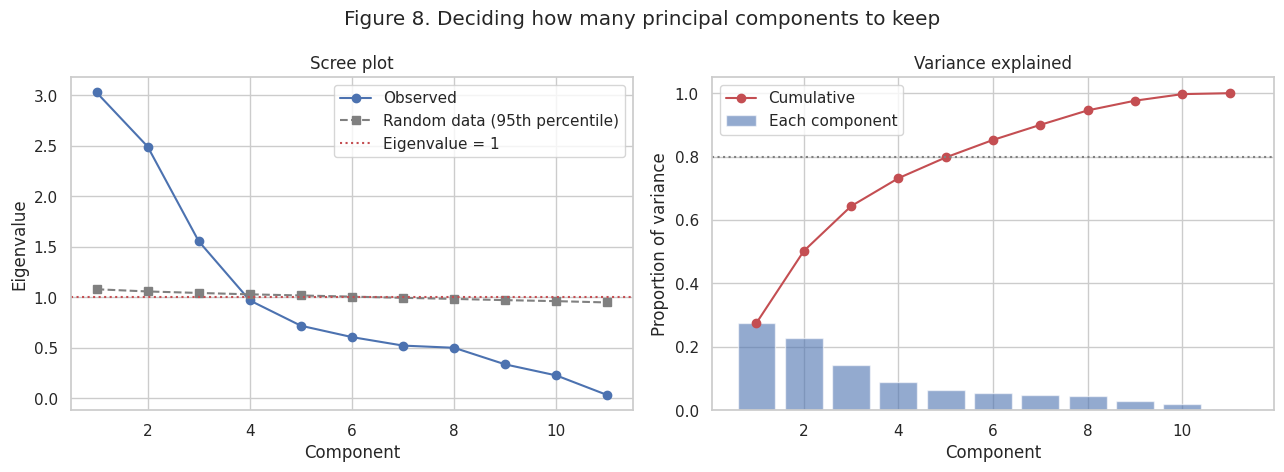

In [13]:
def parallel_analysis(n, p, runs=500, pct=95):
    g = np.random.default_rng(SEED)
    eig = [np.sort(np.linalg.eigvalsh(np.corrcoef(g.standard_normal((n, p)), rowvar=False)))[::-1] for _ in range(runs)]
    return np.percentile(eig, pct, axis=0)

eigvals, eigvecs = np.linalg.eigh(np.corrcoef(Zs, rowvar=False))
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
random_eig = parallel_analysis(*Zs.shape)
share = eigvals / eigvals.sum()

pc_table = pd.DataFrame({"Eigenvalue": eigvals, "Variance": share, "Cumulative": share.cumsum(),
                         "Random_data_95th": random_eig, "Keep": eigvals > random_eig},
                        index=[f"PC{i+1}" for i in range(len(VARS))])
show(pc_table, "C2_pca_eigenvalues")

n_kaiser, n_parallel = int((eigvals > 1).sum()), int((eigvals > random_eig).sum())
n_80 = int(np.searchsorted(share.cumsum(), .80) + 1)
print(f"\nEigenvalue > 1: {n_kaiser} | Parallel analysis: {n_parallel} | Components needed for 80% variance: {n_80}")

x = np.arange(1, len(VARS) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(x, eigvals, "o-", label="Observed")
axes[0].plot(x, random_eig, "s--", color="gray", label="Random data (95th percentile)")
axes[0].axhline(1, color="r", ls=":", label="Eigenvalue = 1")
axes[0].set(xlabel="Component", ylabel="Eigenvalue", title="Scree plot"); axes[0].legend()
axes[1].bar(x, share, alpha=.6, label="Each component")
axes[1].plot(x, share.cumsum(), "ro-", label="Cumulative")
axes[1].axhline(.8, color="gray", ls=":")
axes[1].set(xlabel="Component", ylabel="Proportion of variance", title="Variance explained"); axes[1].legend()
fig.suptitle("Figure 8. Deciding how many principal components to keep")
save_fig("fig08_pca_scree")

In [ ]:
N_PC = n_parallel
print(f"Keeping {N_PC} components, which together explain {share[:N_PC].sum():.1%} of the total variance.")

**Step 4 – Loadings.** A loading is the correlation between a variable and a component. Variables with large
loadings (about |0.40| or more) define what the component means. The sign shows the direction: variables with
opposite signs move in opposite directions along that component.

In [15]:
N_PC = n_parallel
loadings = eigvecs * np.sqrt(eigvals)
for j in range(loadings.shape[1]):
    if loadings[np.abs(loadings[:, j]).argmax(), j] < 0:
        loadings[:, j] *= -1
        eigvecs[:, j] *= -1

pcs = [f"PC{i+1}" for i in range(N_PC)]
L = pd.DataFrame(loadings[:, :N_PC], index=VARS, columns=pcs)
L["Communality"] = (L[pcs] ** 2).sum(axis=1)
show(L, "C3_pca_loadings")

for j, pc in enumerate(pcs):
    top = L[pc][L[pc].abs() >= .40].sort_values(key=np.abs, ascending=False)
    print(f"\n{pc} ({share[j]:.1%} of variance): " + ", ".join(f"{v} ({l:+.2f})" for v, l in top.items()))


C3_pca_loadings
                        PC1    PC2    PC3  Communality
fixed_acidity        -0.416  0.531  0.542        0.748
volatile_acidity     -0.663  0.186 -0.383        0.621
citric_acid           0.265  0.289  0.737        0.697
residual_sugar        0.602  0.521 -0.205        0.676
chlorides            -0.505  0.498 -0.021        0.503
free_sulfur_dioxide   0.750  0.114 -0.167        0.604
total_sulfur_dioxide  0.848  0.138 -0.134        0.757
density              -0.078  0.922 -0.219        0.905
pH                   -0.381 -0.246 -0.568        0.528
sulphates            -0.512  0.303  0.087        0.361
alcohol              -0.185 -0.734  0.326        0.680

PC1 (27.5% of variance): total_sulfur_dioxide (+0.85), free_sulfur_dioxide (+0.75), volatile_acidity (-0.66), residual_sugar (+0.60), sulphates (-0.51), chlorides (-0.50), fixed_acidity (-0.42)

PC2 (22.7% of variance): density (+0.92), alcohol (-0.73), fixed_acidity (+0.53), residual_sugar (+0.52), chlorides (+0.50)

PC

**Step 5 – Pictures.** The loading plot shows each variable as an arrow: arrows pointing the same way are positively
related and long arrows are well represented. The biplot adds the wines themselves, coloured by type.

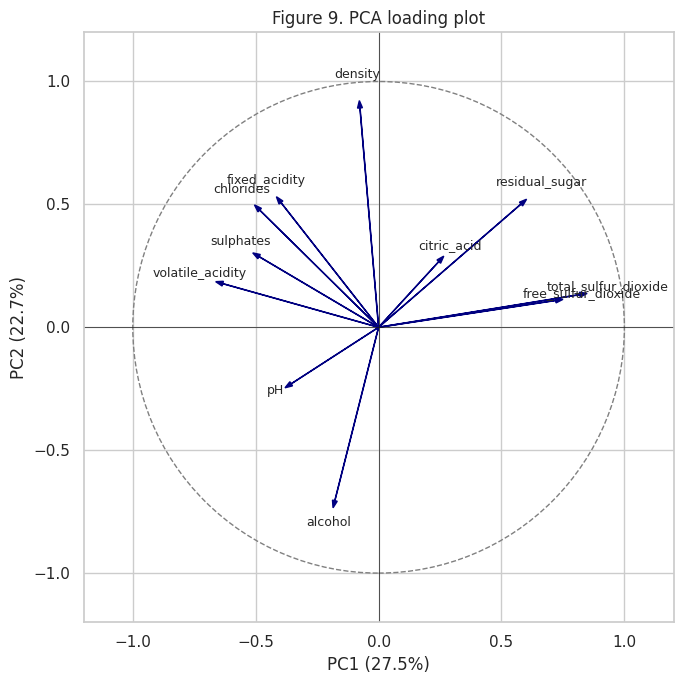

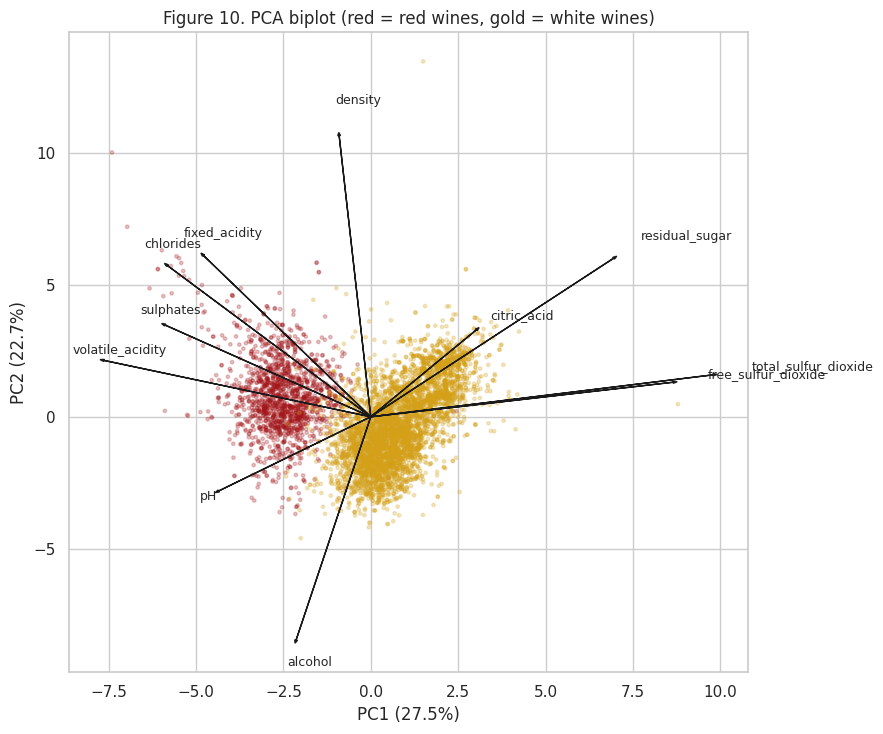


C4_mean_component_scores_by_color
         PC1    PC2    PC3
color                     
Red   -2.515  0.776 -0.184
White  0.821 -0.253  0.060


In [16]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls="--", color="gray"))
for i, v in enumerate(VARS):
    ax.arrow(0, 0, loadings[i, 0], loadings[i, 1], head_width=.02, color="navy", length_includes_head=True)
    ax.text(loadings[i, 0] * 1.1, loadings[i, 1] * 1.1, v, fontsize=9, ha="center")
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), xlabel=f"PC1 ({share[0]:.1%})", ylabel=f"PC2 ({share[1]:.1%})",
       title="Figure 9. PCA loading plot")
ax.set_aspect("equal")
save_fig("fig09_pca_loading_plot")

pc_scores = Zs @ eigvecs[:, :max(N_PC, 2)]
scale = .8 * np.abs(pc_scores[:, :2]).max() / np.abs(loadings[:, :2]).max()
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.scatter(pc_scores[:, 0], pc_scores[:, 1], c=wine["color"].map(PALETTE), s=6, alpha=.25)
for i, v in enumerate(VARS):
    ax.arrow(0, 0, loadings[i, 0] * scale, loadings[i, 1] * scale, color="k", head_width=.08, length_includes_head=True)
    ax.text(loadings[i, 0] * scale * 1.1, loadings[i, 1] * scale * 1.1, v, fontsize=9)
ax.set(xlabel=f"PC1 ({share[0]:.1%})", ylabel=f"PC2 ({share[1]:.1%})",
       title="Figure 10. PCA biplot (red = red wines, gold = white wines)")
save_fig("fig10_pca_biplot")

by_color = pd.DataFrame(pc_scores[:, :N_PC], columns=pcs).assign(color=wine["color"].values).groupby("color")[pcs].mean()
show(by_color, "C4_mean_component_scores_by_color")

## Part D. Exploratory Factor Analysis (EFA)
**Idea:** PCA only summarises the data. Factor analysis goes one step further and asks which *hidden (latent)
characteristics* could explain why variables are correlated, for example an underlying "acidity" factor that
makes several acid-related measurements rise and fall together.



In [17]:
print(f"Bartlett's test: chi-square(55) = {chi2_b:.1f}, {fmt_p(p_b)}")
print(f"Overall KMO = {kmo_all:.2f}  ->  " + ("suitable for factor analysis" if kmo_all >= .60 and p_b < .05
                                              else "factor analysis may not be suitable"))
print("Correlation matrix: Table A4 and Figure 3.")

Bartlett's test: chi-square(55) = 37094.6, p < .001
Overall KMO = 0.41  ->  factor analysis may not be suitable
Correlation matrix: Table A4 and Figure 3.



D1_efa_eigenvalues
     Eigenvalue  Common_factor_eigenvalue  Random_data_95th
F1        3.030                     2.824             1.081
F2        2.494                     2.415             1.059
F3        1.556                     1.335             1.045
F4        0.971                     0.641             1.031
F5        0.720                     0.558             1.020
F6        0.607                     0.412             1.008
F7        0.523                     0.349             0.996
F8        0.502                     0.124             0.985
F9        0.337                     0.072             0.973
F10       0.228                     0.017             0.963
F11       0.033                    -0.000             0.950

Eigenvalue > 1: 3 | Parallel analysis: 3


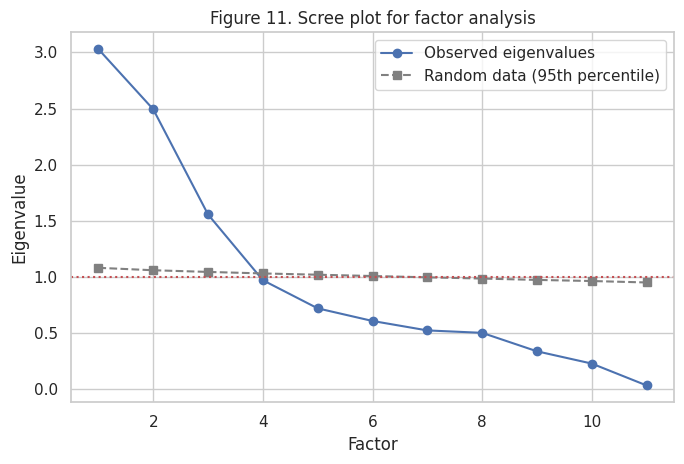

In [18]:
fa_all = FactorAnalyzer(n_factors=len(VARS), rotation=None, method="minres").fit(X)
eig_obs, eig_common = fa_all.get_eigenvalues()
n_fa = int((eig_obs > random_eig).sum())
show(pd.DataFrame({"Eigenvalue": eig_obs, "Common_factor_eigenvalue": eig_common, "Random_data_95th": random_eig},
                  index=[f"F{i+1}" for i in range(len(VARS))]), "D1_efa_eigenvalues")
print(f"\nEigenvalue > 1: {int((eig_obs > 1).sum())} | Parallel analysis: {n_fa}")

plt.figure(figsize=(7, 4.8))
plt.plot(x, eig_obs, "o-", label="Observed eigenvalues")
plt.plot(x, random_eig, "s--", color="gray", label="Random data (95th percentile)")
plt.axhline(1, color="r", ls=":")
plt.xlabel("Factor"); plt.ylabel("Eigenvalue"); plt.legend()
plt.title("Figure 11. Scree plot for factor analysis")
save_fig("fig11_efa_scree")

In [19]:
N_FACTORS = n_fa
print("Number of factors:", N_FACTORS)

Number of factors: 3



D2_efa_loadings
                         F1     F2     F3  Communality  Uniqueness
fixed_acidity         0.745  0.068  0.560        0.874       0.126
volatile_acidity      0.490  0.165 -0.415        0.440       0.560
citric_acid           0.091 -0.053  0.738        0.556       0.444
residual_sugar       -0.338  0.619  0.064        0.502       0.498
chlorides             0.527  0.237 -0.018        0.335       0.665
free_sulfur_dioxide  -0.599  0.297  0.056        0.450       0.550
total_sulfur_dioxide -0.724  0.360  0.106        0.665       0.335
density               0.423  0.952 -0.017        1.085      -0.085
pH                    0.067 -0.025 -0.514        0.270       0.730
sulphates             0.472  0.067  0.022        0.228       0.772
alcohol              -0.040 -0.705  0.067        0.503       0.497

D3_loading_assessment
                         Assessment
fixed_acidity         cross-loading
volatile_acidity      cross-loading
citric_acid           clear loading
residual_sug

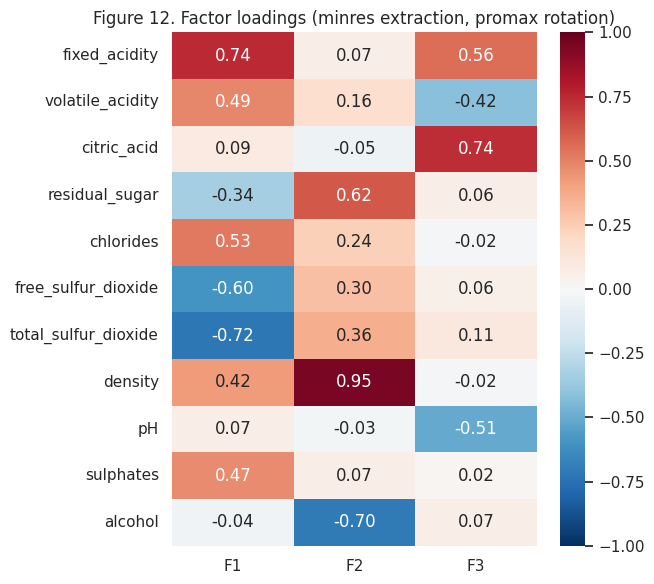

In [20]:
fa = FactorAnalyzer(n_factors=N_FACTORS, rotation="promax", method="minres").fit(X)
factors = [f"F{i+1}" for i in range(N_FACTORS)]
LF = pd.DataFrame(fa.loadings_, index=VARS, columns=factors)
LF["Communality"] = fa.get_communalities()
LF["Uniqueness"] = fa.get_uniquenesses()
show(LF, "D2_efa_loadings")

def classify(row):
    high = row[factors].abs()
    if high.max() < .40:
        return "weak loading"
    return "cross-loading" if (high >= .30).sum() > 1 else "clear loading"

show(LF.apply(classify, axis=1).rename("Assessment").to_frame(), "D3_loading_assessment")

if getattr(fa, "phi_", None) is not None:
    show(pd.DataFrame(fa.phi_, index=factors, columns=factors), "D4_factor_correlations", 2)

ss, prop, cum = fa.get_factor_variance()
show(pd.DataFrame({"SS_loadings": ss, "Proportion_of_variance": prop, "Cumulative": cum}, index=factors), "D5_efa_variance")

plt.figure(figsize=(1.8 + 1.6 * N_FACTORS, 6))
sns.heatmap(LF[factors], annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Figure 12. Factor loadings (minres extraction, promax rotation)")
save_fig("fig12_efa_loadings")

In [22]:
for f in factors:
    top = LF[f][LF[f].abs() >= .40].sort_values(key=np.abs, ascending=False)
    print(f"{f}: " + ", ".join(f"{v} ({l:+.2f})" for v, l in top.items()))

F1: fixed_acidity (+0.74), total_sulfur_dioxide (-0.72), free_sulfur_dioxide (-0.60), chlorides (+0.53), volatile_acidity (+0.49), sulphates (+0.47), density (+0.42)
F2: density (+0.95), alcohol (-0.70), residual_sugar (+0.62)
F3: citric_acid (+0.74), fixed_acidity (+0.56), pH (-0.51), volatile_acidity (-0.42)


## Part E. Putting It Together
The table places the PCA loadings next to the factor-analysis loadings so the two methods can be compared directly.
The main difference: **PCA** builds components from *all* the variance and is a data-reduction tool, while **EFA**
models only the *shared* variance and assumes hidden factors that cause the correlations. They often give
similar groupings, and variables that load strongly in both are the most important to the structure of the data.

In [23]:
compare = pd.concat([L[pcs].add_prefix("PCA_"), LF[factors].add_prefix("EFA_")], axis=1)
compare["PCA_communality"] = L["Communality"]
compare["EFA_communality"] = LF["Communality"]
show(compare, "E1_pca_vs_efa")

both = pd.DataFrame({"PCA_max_loading": L[pcs].abs().max(axis=1), "EFA_max_loading": LF[factors].abs().max(axis=1)})
both["strong_in_both"] = (both["PCA_max_loading"] >= .60) & (both["EFA_max_loading"] >= .60)
show(both, "E2_variables_important_in_both")

summary = pd.Series({
    "MANOVA": f"Pillai's trace = {pt['Value']:.3f}, {fmt_p(pt['Pr > F'])}, partial eta² = {pt['partial_eta2']:.3f}",
    "PCA": f"{N_PC} components explain {share[:N_PC].sum():.1%} of the variance",
    "EFA": f"{N_FACTORS} factors; average communality = {LF['Communality'].mean():.2f}",
})
print("\nSummary of results")
for k, v in summary.items():
    print(f"{k}: {v}")


E1_pca_vs_efa
                      PCA_PC1  PCA_PC2  PCA_PC3  EFA_F1  EFA_F2  EFA_F3  PCA_communality  EFA_communality
fixed_acidity          -0.416    0.531    0.542   0.745   0.068   0.560            0.748            0.874
volatile_acidity       -0.663    0.186   -0.383   0.490   0.165  -0.415            0.621            0.440
citric_acid             0.265    0.289    0.737   0.091  -0.053   0.738            0.697            0.556
residual_sugar          0.602    0.521   -0.205  -0.338   0.619   0.064            0.676            0.502
chlorides              -0.505    0.498   -0.021   0.527   0.237  -0.018            0.503            0.335
free_sulfur_dioxide     0.750    0.114   -0.167  -0.599   0.297   0.056            0.604            0.450
total_sulfur_dioxide    0.848    0.138   -0.134  -0.724   0.360   0.106            0.757            0.665
density                -0.078    0.922   -0.219   0.423   0.952  -0.017            0.905            1.085
pH                     -0.381  

**Limitations to discuss:** (1) the data are observational, so differences between red and white wines cannot be
attributed to colour itself (grape variety, region and process also differ); (2) red and white sample sizes are very
unequal (1,599 vs. 4,898); (3) skewness, outliers and unequal covariance matrices mean the assumptions are only roughly
met; (4) PCA and EFA results depend on the correlation structure of the pooled data, which mixes two wine types, and
factor names are subjective interpretations; (5) the data only describe Vinho Verde wines from Portugal.